# Satellite Orbit Explorer · built during Space Career Week 2026 · GNSS Academy

1. Setup
2. Load GP JSON
3. Parse elements
4. Time window
5. Propagate
6. Orbit summary
7. Plots
8. KML and report

In [1]:
%pip install matplotlib requests


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import requests

MU_EARTH_KM3_S2 = 398600.4418
EARTH_RADIUS_KM = 6378.137

# Keep input and output folders relative to the project directory.
IN_DIR = Path("satellite_orbits") / "input"
OUT_DIR = Path("satellite_orbits") / "output"
IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

STEP_SECONDS = 5
DURATION_HOURS = 24
LIVE_GROUP = None

print("Satellite Orbit Explorer configuration")
print(f"IN_DIR: {IN_DIR}")
print(f"OUT_DIR: {OUT_DIR}")
print(f"STEP_SECONDS: {STEP_SECONDS}")
print(f"DURATION_HOURS: {DURATION_HOURS}")
print(f"LIVE_GROUP: {LIVE_GROUP}")
print(f"MU_EARTH_KM3_S2: {MU_EARTH_KM3_S2}")
print(f"EARTH_RADIUS_KM: {EARTH_RADIUS_KM}")
print("Conventions: UTC-aware datetimes, km, km/s")

Satellite Orbit Explorer configuration
IN_DIR: satellite_orbits/input
OUT_DIR: satellite_orbits/output
STEP_SECONDS: 5
DURATION_HOURS: 24
LIVE_GROUP: None
MU_EARTH_KM3_S2: 398600.4418
EARTH_RADIUS_KM: 6378.137
Conventions: UTC-aware datetimes, km, km/s


OMM JSON is easier to inspect than TLE because each value has a named field instead of relying on fixed column positions. It also uses ISO-formatted dates and supports six-digit catalog numbers, making the data more readable and able to represent newer catalog IDs.

In [4]:
def extract_inputs():
    required = ("orbital_elements.json", "data_manifest.json", "world_map.txt")
    if all((IN_DIR / name).is_file() for name in required):
        return

    print("Drag orbit_workshop_inputs.zip into the notebook's folder (VS Code Explorer panel).")
    deadline = time.monotonic() + 15 * 60
    while time.monotonic() < deadline:
        archives = sorted(Path.cwd().glob("orbit_workshop_inputs*.zip"))
        archive = next((p for p in archives if zipfile.is_zipfile(p)), None)
        if archive is not None:
            with zipfile.ZipFile(archive) as bundle:
                members = {}
                for item in bundle.infolist():
                    name = Path(item.filename).name
                    if name in required and not item.is_dir():
                        members.setdefault(name, item)
                missing = set(required) - members.keys()
                if missing:
                    raise ValueError(f"Upload ZIP is missing required files: {sorted(missing)}")
                for name, item in members.items():
                    (IN_DIR / name).write_bytes(bundle.read(item))
            return
        time.sleep(2)
    raise TimeoutError("No finished orbit_workshop_inputs*.zip found within 15 minutes.")


def read_gp_json(path):
    required = {
        "OBJECT_NAME", "NORAD_CAT_ID", "EPOCH", "MEAN_MOTION", "ECCENTRICITY",
        "INCLINATION", "RA_OF_ASC_NODE", "ARG_OF_PERICENTER", "MEAN_ANOMALY",
    }
    with Path(path).open(encoding="utf-8") as file:
        records = json.load(file)
    if not isinstance(records, list):
        raise ValueError("GP JSON must contain a list of records.")
    for index, record in enumerate(records):
        if not isinstance(record, dict) or required - record.keys():
            missing = sorted(required - record.keys()) if isinstance(record, dict) else sorted(required)
            raise ValueError(f"GP record {index} is missing required OMM fields: {missing}")
    return records


extract_inputs()
sats = read_gp_json(IN_DIR / "orbital_elements.json")
with (IN_DIR / "data_manifest.json").open(encoding="utf-8") as file:
    data_manifest = json.load(file)
source_note = f"CelesTrak GP JSON (OMM fields), retrieved {data_manifest['retrieved_utc']}."
print(source_note)
for sat in sats:
    print(f"{sat['OBJECT_NAME']} | NORAD {sat['NORAD_CAT_ID']} | EPOCH {sat['EPOCH']}")

CelesTrak GP JSON (OMM fields), retrieved 2026-11-10T16:30:32Z.
PULSAR-0 | NORAD 64541 | EPOCH 2026-11-10T04:10:34.900320
GSAT0225 (GALILEO 29) | NORAD 59598 | EPOCH 2026-11-09T08:30:06.579648
SES-5 | NORAD 38652 | EPOCH 2026-11-10T04:02:09.139776
QZS-2 (MICHIBIKI-2) | NORAD 42738 | EPOCH 2026-10-17T15:21:52.982784


| GP field | Symbol | Conversion / unit |
| --- | --- | --- |
| `OBJECT_NAME` | name | text, unchanged |
| `NORAD_CAT_ID` | norad_id | integer, unchanged |
| `EPOCH` | epoch | ISO date-time interpreted as UTC |
| `MEAN_MOTION` | n | rev/day × 2π / 86400 → rad/s |
| `ECCENTRICITY` | e | decimal, dimensionless, unchanged |
| `INCLINATION` | i | degrees × π / 180 → radians |
| `RA_OF_ASC_NODE` | raan | degrees × π / 180 → radians |
| `ARG_OF_PERICENTER` | argp | degrees × π / 180 → radians |
| `MEAN_ANOMALY` | M₀ | degrees × π / 180 → radians |
| Derived from n | a | (μ / n²)^(1/3) → km |

GP values are SGP4 mean elements; using them in our two-body Kepler model is an educational approximation, not precision orbit prediction.

In [5]:
def parse_gp_epoch(text):
    return datetime.fromisoformat(text.rstrip("Z")).replace(tzinfo=timezone.utc)


def parse_gp_elements(rec):
    name = rec["OBJECT_NAME"]
    norad_id = int(rec["NORAD_CAT_ID"])
    n_rad_s = 2 * math.pi * rec["MEAN_MOTION"] / 86400
    return {
        "name": name,
        "norad_id": norad_id,
        "label": f"{name} [{norad_id}]",
        "epoch": parse_gp_epoch(rec["EPOCH"]),
        "n_rad_s": n_rad_s,
        "a_km": (MU_EARTH_KM3_S2 / n_rad_s**2) ** (1 / 3),
        "e": rec["ECCENTRICITY"],
        "i_rad": math.radians(rec["INCLINATION"]),
        "raan_rad": math.radians(rec["RA_OF_ASC_NODE"]),
        "argp_rad": math.radians(rec["ARG_OF_PERICENTER"]),
        "M0_rad": math.radians(rec["MEAN_ANOMALY"]),
    }


def elements_table(elements):
    headers = ["Name", "NORAD", "Epoch (UTC)", "a [km]", "e", "i [deg]", "RAAN [deg]", "argp [deg]", "M0 [deg]"]
    rows = [
        [
            item["name"], str(item["norad_id"]), item["epoch"].isoformat(),
            f"{item['a_km']:.3f}", f"{item['e']:.7f}",
            f"{math.degrees(item['i_rad']):.4f}", f"{math.degrees(item['raan_rad']):.4f}",
            f"{math.degrees(item['argp_rad']):.4f}", f"{math.degrees(item['M0_rad']):.4f}",
        ]
        for item in elements
    ]
    widths = [max([len(header)] + [len(row[i]) for row in rows]) for i, header in enumerate(headers)]
    lines = [" | ".join(header.ljust(widths[i]) for i, header in enumerate(headers))]
    lines.append("-+-".join("-" * width for width in widths))
    lines.extend(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)) for row in rows)
    return lines


if "sats" not in globals():
    raise RuntimeError("Run Stage 2 first to load GP records into sats.")
elements = [parse_gp_elements(s) for s in sats]
print("\n".join(elements_table(elements)))

Name                  | NORAD | Epoch (UTC)                      | a [km]    | e         | i [deg] | RAAN [deg] | argp [deg] | M0 [deg]
----------------------+-------+----------------------------------+-----------+-----------+---------+------------+------------+---------
PULSAR-0              | 64541 | 2026-11-10T04:10:34.900320+00:00 | 6880.971  | 0.0004075 | 97.4838 | 67.6279    | 54.1589    | 306.0025
GSAT0225 (GALILEO 29) | 59598 | 2026-11-09T08:30:06.579648+00:00 | 29600.256 | 0.0001590 | 55.2189 | 97.0227    | 171.2097   | 226.8931
SES-5                 | 38652 | 2026-11-10T04:02:09.139776+00:00 | 42164.283 | 0.0001910 | 0.0509  | 32.2008    | 188.0056   | 254.6756
QZS-2 (MICHIBIKI-2)   | 42738 | 2026-10-17T15:21:52.982784+00:00 | 42170.355 | 0.0745209 | 39.2498 | 241.3539   | 270.8929   | 243.8231


Each record is propagated from its own epoch, so differences between that epoch and the common start can increase the propagation error. The workshop’s QZS-2 record dates from 17 October 2026, making its offset especially important to notice.

In [6]:
if "elements" not in globals() or not elements:
    raise RuntimeError("Run Stage 3 first to create elements.")
if "DURATION_HOURS" not in globals() or "STEP_SECONDS" not in globals():
    raise RuntimeError("Run Stage 1 first to set the time-window configuration.")

start = max(item["epoch"] for item in elements).replace(
    hour=0, minute=0, second=0, microsecond=0
)
end = start + timedelta(hours=DURATION_HOURS)
n_points = (end - start) // timedelta(seconds=STEP_SECONDS) + 1
times = [start + timedelta(seconds=i * STEP_SECONDS) for i in range(n_points)]

print(f"Window: {start.isoformat()} to {end.isoformat()} (UTC, inclusive)")
print(f"n_points: {n_points}")
for item in elements:
    offset_days = (start - item["epoch"]).total_seconds() / 86400
    status = "STALE RECORD" if offset_days > 7 else "OK"
    print(f"{item['label']}: start - epoch = {offset_days:.3f} days [{status}]")

Window: 2026-11-10T00:00:00+00:00 to 2026-11-11T00:00:00+00:00 (UTC, inclusive)
n_points: 17281
PULSAR-0 [64541]: start - epoch = -0.174 days [OK]
GSAT0225 (GALILEO 29) [59598]: start - epoch = 0.646 days [OK]
SES-5 [38652]: start - epoch = -0.168 days [OK]
QZS-2 (MICHIBIKI-2) [42738]: start - epoch = 23.360 days [STALE RECORD]


Kepler’s equation gives the eccentric anomaly from the mean anomaly; from that we find the satellite’s position along its orbit. We rotate that position into Earth-fixed coordinates using GMST, convert it to latitude, longitude, and altitude, and use vis-viva for speed.

In [7]:
if "elements" not in globals() or not elements:
    raise RuntimeError("Run Stage 3 first to create elements.")
if "times" not in globals() or not times:
    raise RuntimeError("Run Stage 4 first to create the common time grid.")


def solve_kepler(M, e):
    E = math.pi if e > 0.8 else M
    for _ in range(50):
        delta = (E - e * math.sin(E) - M) / (1 - e * math.cos(E))
        E -= delta
        if abs(delta) < 1e-12:
            return E
    raise RuntimeError("Kepler solver did not converge in 50 iterations.")


def gmst_rad(t):
    J2000 = datetime(2000, 1, 1, 12, tzinfo=timezone.utc)
    d = (t - J2000).total_seconds() / 86400
    T = d / 36525
    theta = (
        280.46061837 + 360.98564736629 * d
        + 0.000387933 * T**2 - T**3 / 38710000
    ) % 360
    return math.radians(theta)


def propagate(el, times):
    points = []
    for t in times:
        # 1) Advance mean anomaly from this object's epoch.
        M = (el["M0_rad"] + el["n_rad_s"] * (t - el["epoch"]).total_seconds()) % (2 * math.pi)
        # 2) Solve Kepler's equation for eccentric anomaly.
        E = solve_kepler(M, el["e"])
        # 3) Find orbital radius, true anomaly, and argument of latitude.
        r = el["a_km"] * (1 - el["e"] * math.cos(E))
        nu = math.atan2(
            math.sqrt(1 - el["e"]**2) * math.sin(E),
            math.cos(E) - el["e"],
        )
        u = el["argp_rad"] + nu
        # 4) Rotate the orbital position into Earth-centered inertial axes.
        x = r * (
            math.cos(el["raan_rad"]) * math.cos(u)
            - math.sin(el["raan_rad"]) * math.sin(u) * math.cos(el["i_rad"])
        )
        y = r * (
            math.sin(el["raan_rad"]) * math.cos(u)
            + math.cos(el["raan_rad"]) * math.sin(u) * math.cos(el["i_rad"])
        )
        z = r * math.sin(u) * math.sin(el["i_rad"])
        # 5) Rotate inertial coordinates into Earth-fixed axes using GMST.
        theta = gmst_rad(t)
        x_fixed = math.cos(theta) * x + math.sin(theta) * y
        y_fixed = -math.sin(theta) * x + math.cos(theta) * y
        # 6) Convert Earth-fixed position to spherical coordinates.
        lat = math.atan2(z, math.hypot(x_fixed, y_fixed))
        lon = math.atan2(y_fixed, x_fixed)
        # 7) Compute orbital speed from the vis-viva equation.
        speed = math.sqrt(MU_EARTH_KM3_S2 * (2 / r - 1 / el["a_km"]))
        points.append({
            "time": t,
            "lat_deg": math.degrees(lat),
            "lon_deg": math.degrees(lon),
            "alt_km": r - EARTH_RADIUS_KM,
            "speed_km_s": speed,
        })
    return points


tracks = [propagate(el, times) for el in elements]

J2000 = datetime(2000, 1, 1, 12, tzinfo=timezone.utc)
assert abs(math.degrees(gmst_rad(J2000)) - 280.46061837) < 0.01
print("GMST at J2000 check passed.")

for eccentricity in [0, 0.1, 0.7, 0.9]:
    for mean_anomaly in [0.1, 1, 3, 6]:
        E = solve_kepler(mean_anomaly, eccentricity)
        assert abs(E - eccentricity * math.sin(E) - mean_anomaly) < 1e-10
print("Kepler residual checks passed.")

ses_track = next(
    (track for el, track in zip(elements, tracks) if el["norad_id"] == 38652),
    None,
)
if ses_track is None:
    print("SES-5 longitude check skipped (NORAD 38652 not in data).")
else:
    assert all(4 <= point["lon_deg"] <= 6 for point in ses_track)
    print("SES-5 longitude check passed.")

for el, track in zip(elements, tracks):
    for label, index in [
        ("first", 0),
        ("middle", len(track) // 2),
        ("last", len(track) - 1),
    ]:
        point = track[index]
        print(
            f"{el['label']} {label}: "
            f"time={point['time'].isoformat()}, "
            f"lat={point['lat_deg']:.3f} deg, "
            f"lon={point['lon_deg']:.3f} deg, "
            f"alt={point['alt_km']:.3f} km, "
            f"speed={point['speed_km_s']:.6f} km/s"
        )

GMST at J2000 check passed.
Kepler residual checks passed.
SES-5 longitude check passed.
PULSAR-0 [64541] first: time=2026-11-10T00:00:00+00:00, lat=51.994 deg, lon=-151.863 deg, alt=502.023 km, speed=7.611937 km/s
PULSAR-0 [64541] middle: time=2026-11-10T12:00:00+00:00, lat=-14.793 deg, lon=-160.045 deg, alt=501.832 km, speed=7.612149 km/s
PULSAR-0 [64541] last: time=2026-11-11T00:00:00+00:00, lat=-22.732 deg, lon=-165.681 deg, alt=505.232 km, speed=7.608389 km/s
GSAT0225 (GALILEO 29) [59598] first: time=2026-11-10T00:00:00+00:00, lat=52.284 deg, lon=111.761 deg, alt=23222.677 km, speed=3.669551 km/s
GSAT0225 (GALILEO 29) [59598] middle: time=2026-11-10T12:00:00+00:00, lat=17.322 deg, lon=-120.128 deg, alt=23226.194 km, speed=3.669115 km/s
GSAT0225 (GALILEO 29) [59598] last: time=2026-11-11T00:00:00+00:00, lat=-25.704 deg, lon=27.338 deg, alt=23226.450 km, speed=3.669084 km/s
SES-5 [38652] first: time=2026-11-10T00:00:00+00:00, lat=0.019 deg, lon=5.005 deg, alt=35793.962 km, speed=3.0

Orbit Summary
Period, perigee, apogee and speed range for every satellite.

In [8]:
if "elements" not in globals() or not elements:
    raise RuntimeError("Run Stage 3 first to create elements.")
if "tracks" not in globals() or not tracks:
    raise RuntimeError("Run Stage 5 first to create propagated tracks.")


def orbit_summary(el, pts):
    return {
        "name": el["name"],
        "norad_id": el["norad_id"],
        "period_h": 2 * math.pi / el["n_rad_s"] / 3600,
        "perigee_km": el["a_km"] * (1 - el["e"]) - EARTH_RADIUS_KM,
        "apogee_km": el["a_km"] * (1 + el["e"]) - EARTH_RADIUS_KM,
        "e": el["e"],
        "i_deg": math.degrees(el["i_rad"]),
        "min_speed_km_s": min(p["speed_km_s"] for p in pts),
        "max_speed_km_s": max(p["speed_km_s"] for p in pts),
    }


def summary_table(summaries):
    headers = [
        "Name", "NORAD", "Period [h]", "Perigee [km]", "Apogee [km]",
        "e", "i [deg]", "Min speed [km/s]", "Max speed [km/s]",
    ]
    rows = [
        [
            item["name"], str(item["norad_id"]), f"{item['period_h']:.3f}",
            f"{item['perigee_km']:.3f}", f"{item['apogee_km']:.3f}",
            f"{item['e']:.6f}", f"{item['i_deg']:.4f}",
            f"{item['min_speed_km_s']:.6f}", f"{item['max_speed_km_s']:.6f}",
        ]
        for item in summaries
    ]
    widths = [
        max([len(header)] + [len(row[i]) for row in rows])
        for i, header in enumerate(headers)
    ]
    lines = [
        " | ".join(header.ljust(widths[i]) for i, header in enumerate(headers)),
        "-+-".join("-" * width for width in widths),
    ]
    lines.extend(
        " | ".join(value.ljust(widths[i]) for i, value in enumerate(row))
        for row in rows
    )
    return lines


summaries = [orbit_summary(el, pts) for el, pts in zip(elements, tracks)]
print("\n".join(summary_table(summaries)))

galileo = next((item for item in summaries if item["norad_id"] == 59598), None)
if galileo is None:
    print("Galileo 29 period check skipped (NORAD 59598 not in data).")
else:
    assert 14.0 <= galileo["period_h"] <= 14.2
    print("Galileo 29 period check passed.")

Name                  | NORAD | Period [h] | Perigee [km] | Apogee [km] | e        | i [deg] | Min speed [km/s] | Max speed [km/s]
----------------------+-------+------------+--------------+-------------+----------+---------+------------------+-----------------
PULSAR-0              | 64541 | 1.578      | 500.030      | 505.638     | 0.000408 | 97.4838 | 7.607939         | 7.614143        
GSAT0225 (GALILEO 29) | 59598 | 14.078     | 23217.411    | 23226.827   | 0.000159 | 55.2189 | 3.669037         | 3.670204        
SES-5                 | 38652 | 23.935     | 35778.092    | 35794.200   | 0.000191 | 0.0509  | 3.074069         | 3.075243        
QZS-2 (MICHIBIKI-2)   | 42738 | 23.940     | 32649.646    | 38934.790   | 0.074521 | 39.2498 | 2.853259         | 3.312755        
Galileo 29 period check passed.


Creating Plots

Coastline: 309 segments, 10266 points
Longitude range: -180.000421 to 180.000421
Latitude range: -85.582706 to 83.651838


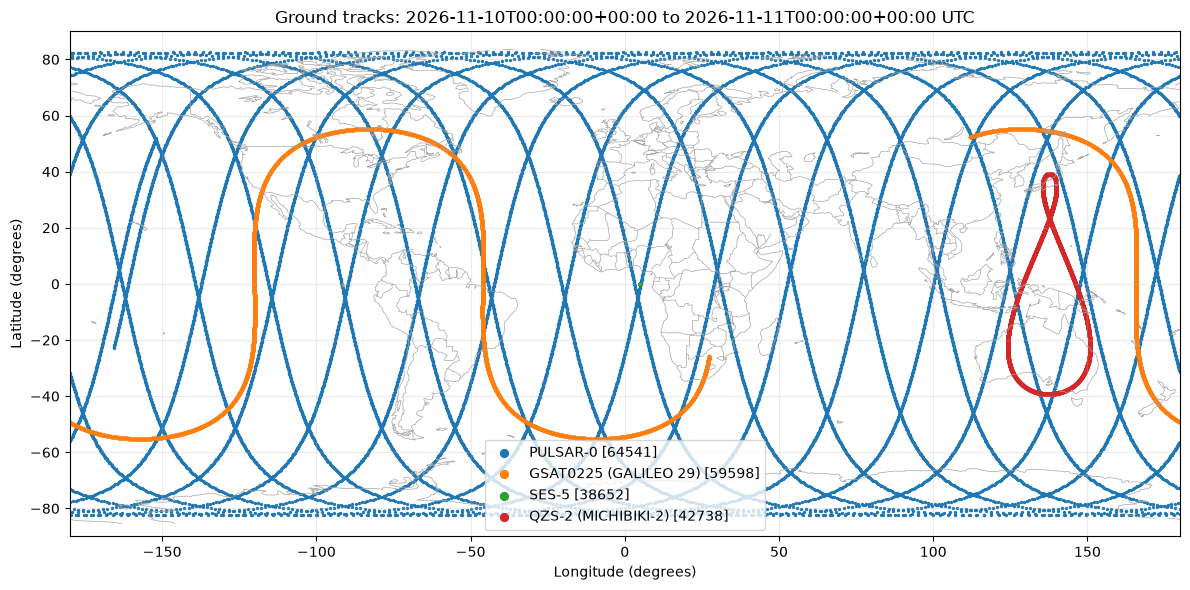

Saved satellite_orbits/output/ground_tracks.png (649610 bytes)


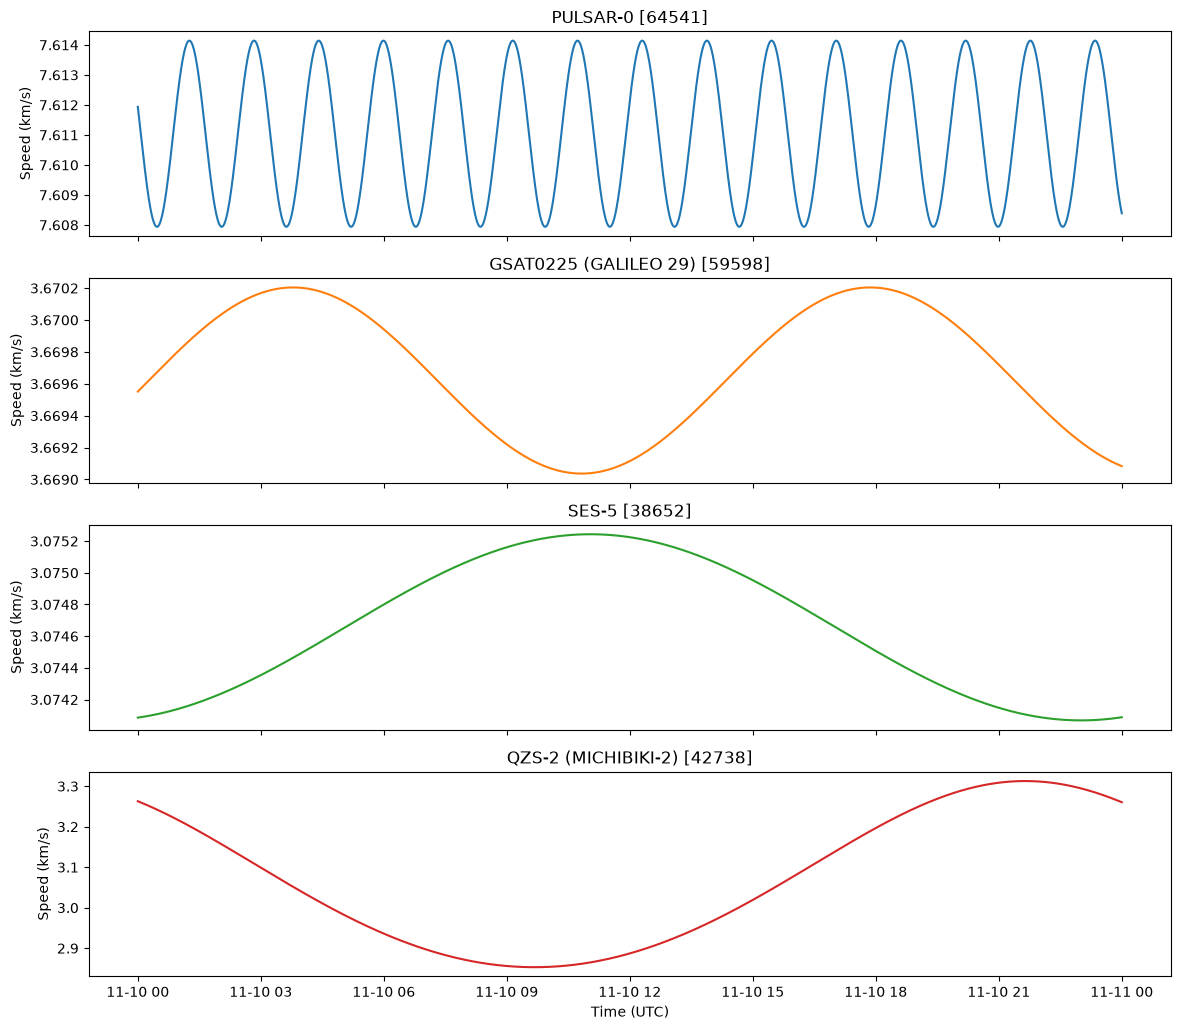

Saved satellite_orbits/output/velocity_timeseries.png (329958 bytes)


In [9]:
if "elements" not in globals() or not elements:
    raise RuntimeError("Run Stage 3 first to load satellite elements.")
if "tracks" not in globals() or not tracks:
    raise RuntimeError("Run Stage 5 first to propagate satellite tracks.")
if "times" not in globals() or not times:
    raise RuntimeError("Run Stage 4 first to create the common time grid.")

COLORS = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
if len(elements) > len(COLORS):
    raise ValueError("Stage 7 has colors for only four satellites.")


def load_coastline(path):
    segments, segment = [], []
    with Path(path).open(encoding="utf-8") as file:
        for line_number, line in enumerate(file, 1):
            if not line.strip():
                if segment:
                    segments.append(segment)
                    segment = []
                continue
            try:
                latitude, longitude = map(float, line.split())
            except ValueError as exc:
                raise ValueError(
                    f"Invalid coastline line {line_number} in {path}; "
                    "expected latitude longitude."
                ) from exc
            if not math.isfinite(latitude) or not math.isfinite(longitude):
                raise ValueError(f"Non-finite coastline coordinate at {path}:{line_number}.")
            if not -180.01 <= longitude <= 180.01:
                raise ValueError(
                    f"Longitude outside [-180.01, 180.01] at {path}:{line_number}: {longitude}."
                )
            if not -90.01 <= latitude <= 90.01:
                raise ValueError(
                    f"Latitude outside [-90.01, 90.01] at {path}:{line_number}: {latitude}."
                )
            segment.append((longitude, latitude))
    if segment:
        segments.append(segment)
    if not segments:
        raise ValueError(f"No coastline coordinates found in {path}.")
    return segments


coastline = load_coastline(IN_DIR / "world_map.txt")
coastline_points = [point for segment in coastline for point in segment]
longitudes = [point[0] for point in coastline_points]
latitudes = [point[1] for point in coastline_points]
print(f"Coastline: {len(coastline)} segments, {len(coastline_points)} points")
print(f"Longitude range: {min(longitudes):.6f} to {max(longitudes):.6f}")
print(f"Latitude range: {min(latitudes):.6f} to {max(latitudes):.6f}")

fig, ax = plt.subplots(figsize=(12, 6))
for segment in coastline:
    draw_lon, draw_lat = [], []
    for longitude, latitude in segment:
        if draw_lon and abs(longitude - draw_lon[-1]) > 180:
            ax.plot(draw_lon, draw_lat, color="0.65", linewidth=0.5)
            draw_lon, draw_lat = [], []
        draw_lon.append(longitude)
        draw_lat.append(latitude)
    if draw_lon:
        ax.plot(draw_lon, draw_lat, color="0.65", linewidth=0.5)

for el, points, color in zip(elements, tracks, COLORS):
    ax.scatter(
        [point["lon_deg"] for point in points],
        [point["lat_deg"] for point in points],
        s=2, color=color, label=el["label"],
    )
ax.set(
    xlim=(-180, 180), ylim=(-90, 90),
    xlabel="Longitude (degrees)", ylabel="Latitude (degrees)",
)
ax.set_title(f"Ground tracks: {start.isoformat()} to {end.isoformat()} UTC")
ax.grid(True, alpha=0.25)
ax.legend(markerscale=4)
fig.tight_layout()
ground_path = OUT_DIR / "ground_tracks.png"
fig.savefig(ground_path, dpi=200)
plt.show()
print(f"Saved {ground_path} ({ground_path.stat().st_size} bytes)")
plt.close(fig)

fig, axes = plt.subplots(
    len(elements), 1, figsize=(12, 2.6 * len(elements)), sharex=True
)
if len(elements) == 1:
    axes = [axes]
for ax, el, points, color in zip(axes, elements, tracks, COLORS):
    ax.plot(times, [point["speed_km_s"] for point in points], color=color)
    ax.ticklabel_format(axis="y", useOffset=False)
    ax.set_ylabel("Speed (km/s)")
    ax.set_title(el["label"])
axes[-1].set_xlabel("Time (UTC)")
fig.tight_layout()
velocity_path = OUT_DIR / "velocity_timeseries.png"
fig.savefig(velocity_path, dpi=200)
plt.show()
print(f"Saved {velocity_path} ({velocity_path.stat().st_size} bytes)")
plt.close(fig)

The plotted claims are consistent with the data. PULSAR-0 makes many west-shifting passes; its latitude range is about ±82.5°, and its 97.48° inclination is retrograde and near-polar, compatible with a sun-synchronous orbit (though this two-body model cannot verify sun-synchronous precession). Galileo 29 makes a wide wave, spanning about ±55.2° latitude.

SES-5 appears as one dot: its track stays between about 4.988° and 5.031° longitude and ±0.051° latitude, consistent with its nearly circular, equatorial orbit and period of 23.935 hours. QZS-2 makes an asymmetric figure-8; its period is 23.940 hours, approximately one sidereal day, and the highest-altitude track point is at 39.244° north latitude. Its eccentricity (0.0745) and inclination (39.25°) identify it as an inclined geosynchronous orbit, not a geostationary one.

Eccentric orbits move faster near perigee because the smaller orbital radius increases speed in the vis-viva relation.

# Stage 8: KML and report

This stage exports the satellite tracks for Google Earth and writes a text report from the orbit summaries. It checks the KML geometry and packages the plots, KML files, and report into one ZIP.

In [12]:
if "elements" not in globals() or not elements:
    raise RuntimeError("Run Stage 3 first to load satellite elements.")
if "tracks" not in globals() or len(tracks) != len(elements):
    raise RuntimeError("Run Stage 5 first to create a track for every satellite.")
if "summaries" not in globals() or len(summaries) != len(elements):
    raise RuntimeError("Run Stage 6 first to create orbit summaries.")
if "COLORS" not in globals() or len(COLORS) < len(elements):
    raise RuntimeError("Run Stage 7 first to define a color for every satellite.")
if "STEP_SECONDS" not in globals() or STEP_SECONDS <= 0 or 60 % STEP_SECONDS:
    raise ValueError("60 seconds must be a multiple of STEP_SECONDS for KML animation.")

plot_paths = [OUT_DIR / "ground_tracks.png", OUT_DIR / "velocity_timeseries.png"]
missing = [str(path) for path in plot_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Create the Stage 7 plots before exporting: {missing}")

KML_NS = "http://www.opengis.net/kml/2.2"
GX_NS = "http://www.google.com/kml/ext/2.2"
ET.register_namespace("", KML_NS)
ET.register_namespace("gx", GX_NS)
q = lambda tag: f"{{{KML_NS}}}{tag}"
gx = lambda tag: f"{{{GX_NS}}}{tag}"


def kml_color(color):
    rgb = to_hex(color).lstrip("#")
    return "ff" + rgb[4:6] + rgb[2:4] + rgb[0:2]


def make_document(title):
    root = ET.Element(q("kml"))
    document = ET.SubElement(root, q("Document"))
    ET.SubElement(document, q("name")).text = title
    for el, color in zip(elements, COLORS):
        style = ET.SubElement(document, q("Style"), id=f"sat_{el['norad_id']}")
        line = ET.SubElement(style, q("LineStyle"))
        ET.SubElement(line, q("color")).text = kml_color(color)
        icon_style = ET.SubElement(style, q("IconStyle"))
        ET.SubElement(icon_style, q("color")).text = kml_color(color)
        icon = ET.SubElement(icon_style, q("Icon"))
        ET.SubElement(icon, q("href")).text = (
            "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"
        )
    return root, document


def write_kml(root, path):
    ET.indent(root, space="  ")
    ET.ElementTree(root).write(path, encoding="utf-8", xml_declaration=True)


ecef_path = OUT_DIR / "orbit_tracks_ecef.kml"
root, document = make_document("Multi-Satellite Orbits | Earth-fixed")
for el, points in zip(elements, tracks):
    placemark = ET.SubElement(document, q("Placemark"))
    ET.SubElement(placemark, q("name")).text = el["label"]
    ET.SubElement(placemark, q("styleUrl")).text = f"#sat_{el['norad_id']}"
    line = ET.SubElement(placemark, q("LineString"))
    ET.SubElement(line, q("altitudeMode")).text = "absolute"
    ET.SubElement(line, q("coordinates")).text = " ".join(
        f"{p['lon_deg']:.6f},{p['lat_deg']:.6f},{p['alt_km'] * 1000:.1f}"
        for p in points
    )
write_kml(root, ecef_path)

animation_path = OUT_DIR / "orbit_animation.kml"
root, document = make_document("Multi-Satellite Ground Tracks | Animation")
stride = 60 // STEP_SECONDS
for el, points in zip(elements, tracks):
    sampled = points[::stride]
    if not sampled:
        raise ValueError(f"No animation points for {el['label']}.")
    placemark = ET.SubElement(document, q("Placemark"))
    ET.SubElement(placemark, q("name")).text = el["label"]
    ET.SubElement(placemark, q("styleUrl")).text = f"#sat_{el['norad_id']}"
    multi = ET.SubElement(placemark, gx("MultiTrack"))

    # Start a new timed track at each longitude wrap.
    segments, segment = [], []
    for point in sampled:
        if segment and abs(point["lon_deg"] - segment[-1]["lon_deg"]) > 180:
            segments.append(segment)
            segment = []
        segment.append(point)
    if segment:
        segments.append(segment)

    for points_in_segment in segments:
        track = ET.SubElement(multi, gx("Track"))
        ET.SubElement(track, q("altitudeMode")).text = "clampToGround"
        for point in points_in_segment:
            stamp = point["time"].astimezone(timezone.utc).strftime(
                "%Y-%m-%dT%H:%M:%SZ"
            )
            ET.SubElement(track, q("when")).text = stamp
        for point in points_in_segment:
            ET.SubElement(track, gx("coord")).text = (
                f"{point['lon_deg']:.6f} {point['lat_deg']:.6f} 0"
            )
write_kml(root, animation_path)

report_path = OUT_DIR / "orbit_report.txt"
report = [
    "Satellite Orbit Report - built during Space Career Week 2026, GNSS Academy",
    source_note,
    f"Window: {start.isoformat()} to {end.isoformat()} UTC; step: {STEP_SECONDS} seconds",
    "Model caveat: two-body, spherical Earth, geocentric latitude; Google Earth uses WGS-84, so positions can differ by up to about 20 km.",
    "",
    "Orbit summary:",
    *summary_table(summaries),
    "",
    "Kepler elements:",
    *elements_table(elements),
]
report_path.write_text("\n".join(report) + "\n", encoding="utf-8")

# Re-parse both exports and count their points.
ecef_tree = ET.parse(ecef_path)
anim_tree = ET.parse(animation_path)
for placemark in ecef_tree.findall(f".//{q('Placemark')}"):
    name = placemark.findtext(q("name"))
    coordinates = placemark.findtext(
        f"{q('LineString')}/{q('coordinates')}", default=""
    ).split()
    print(f"ECEF {name}: {len(coordinates)} coordinates")

first_pm = ecef_tree.find(f".//{q('Placemark')}")
first_coord = first_pm.findtext(
    f"{q('LineString')}/{q('coordinates')}"
).split()[0]
print(f"First ECEF coordinate ({first_pm.findtext(q('name'))}): {first_coord}")

for placemark in anim_tree.findall(f".//{q('Placemark')}"):
    name = placemark.findtext(q("name"))
    tracks_in_pm = placemark.findall(f".//{gx('Track')}")
    point_count = sum(len(track.findall(q("when"))) for track in tracks_in_pm)
    print(f"Animation {name}: {len(tracks_in_pm)} gx:Track elements, {point_count} points")

outputs = [*plot_paths, ecef_path, animation_path, report_path]
zip_path = OUT_DIR / "satellite_orbit_outputs.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in outputs:
        archive.write(path, arcname=path.name)

print(f"ZIP: {zip_path}")
for path in outputs:
    print(f"{path.name}: {path.stat().st_size} bytes")
print(f"{zip_path.name}: {zip_path.stat().st_size} bytes")

ECEF PULSAR-0 [64541]: 17281 coordinates
ECEF GSAT0225 (GALILEO 29) [59598]: 17281 coordinates
ECEF SES-5 [38652]: 17281 coordinates
ECEF QZS-2 (MICHIBIKI-2) [42738]: 17281 coordinates
First ECEF coordinate (PULSAR-0 [64541]): -151.863041,51.993997,502023.0
Animation PULSAR-0 [64541]: 17 gx:Track elements, 1441 points
Animation GSAT0225 (GALILEO 29) [59598]: 2 gx:Track elements, 1441 points
Animation SES-5 [38652]: 1 gx:Track elements, 1441 points
Animation QZS-2 (MICHIBIKI-2) [42738]: 1 gx:Track elements, 1441 points
ZIP: satellite_orbits/output/satellite_orbit_outputs.zip
ground_tracks.png: 649610 bytes
velocity_timeseries.png: 329958 bytes
orbit_tracks_ecef.kml: 2156706 bytes
orbit_animation.kml: 566923 bytes
orbit_report.txt: 1993 bytes
satellite_orbit_outputs.zip: 1810608 bytes


In [13]:
if "elements" not in globals() or not elements:
    raise RuntimeError("Run Stage 3 first to load satellite elements.")
if "tracks" not in globals() or len(tracks) != len(elements):
    raise RuntimeError("Run Stage 5 first to create a track for every satellite.")
if len(COLORS) < len(elements):
    raise ValueError("Not enough colors for all satellites.")
if STEP_SECONDS <= 0 or 60 % STEP_SECONDS:
    raise ValueError("60 seconds must be a multiple of STEP_SECONDS.")

KML_NS = "http://www.opengis.net/kml/2.2"
GX_NS = "http://www.google.com/kml/ext/2.2"
ET.register_namespace("", KML_NS)
ET.register_namespace("gx", GX_NS)
kml = lambda name: f"{{{KML_NS}}}{name}"
GX_MULTITRACK = f"{{{GX_NS}}}MultiTrack"
GX_TRACK = f"{{{GX_NS}}}Track"
GX_COORD = f"{{{GX_NS}}}coord"


def kml_color(color):
    rgb = to_hex(color).lstrip("#")
    return "ff" + rgb[4:6] + rgb[2:4] + rgb[0:2]


root = ET.Element(kml("kml"))
document = ET.SubElement(root, kml("Document"))
ET.SubElement(document, kml("name")).text = "Multi-Satellite Ground Tracks | Animation"

for el, color in zip(elements, COLORS):
    style = ET.SubElement(document, kml("Style"), id=f"sat_{el['norad_id']}")
    line_style = ET.SubElement(style, kml("LineStyle"))
    ET.SubElement(line_style, kml("color")).text = kml_color(color)
    icon_style = ET.SubElement(style, kml("IconStyle"))
    ET.SubElement(icon_style, kml("color")).text = kml_color(color)
    icon = ET.SubElement(icon_style, kml("Icon"))
    ET.SubElement(icon, kml("href")).text = (
        "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"
    )

stride = 60 // STEP_SECONDS
for el, points in zip(elements, tracks):
    sampled = points[::stride]
    if not sampled:
        raise ValueError(f"No animation points for {el['label']}.")

    placemark = ET.SubElement(document, kml("Placemark"))
    ET.SubElement(placemark, kml("name")).text = el["label"]
    ET.SubElement(placemark, kml("styleUrl")).text = f"#sat_{el['norad_id']}"
    multi = ET.SubElement(placemark, GX_MULTITRACK)

    segments, segment = [], []
    for point in sampled:
        if segment and abs(point["lon_deg"] - segment[-1]["lon_deg"]) > 180:
            segments.append(segment)
            segment = []
        segment.append(point)
    if segment:
        segments.append(segment)

    for points_in_segment in segments:
        if not points_in_segment:
            raise ValueError(f"Empty animation segment for {el['label']}.")
        track = ET.SubElement(multi, GX_TRACK)
        ET.SubElement(track, kml("altitudeMode")).text = "clampToGround"
        for point in points_in_segment:
            stamp = point["time"].astimezone(timezone.utc).strftime(
                "%Y-%m-%dT%H:%M:%SZ"
            )
            ET.SubElement(track, kml("when")).text = stamp
        for point in points_in_segment:
            ET.SubElement(track, GX_COORD).text = (
                f"{point['lon_deg']:.6f} {point['lat_deg']:.6f} 0"
            )

animation_path = OUT_DIR / "orbit_animation.kml"
ET.indent(root, space="  ")
ET.ElementTree(root).write(animation_path, encoding="utf-8", xml_declaration=True)

print("First 25 lines of orbit_animation.kml:")
with animation_path.open(encoding="utf-8") as file:
    for number, line in enumerate(file, 1):
        if number > 25:
            break
        print(f"{number}: {line.rstrip()}")

parsed_root = ET.parse(animation_path).getroot()
print(f"Root tag: {parsed_root.tag}")
print(f"Root attributes: {parsed_root.attrib}")
namespace_declarations = {}
for event, value in ET.iterparse(
    animation_path, events=("start-ns", "start")
):
    if event == "start":
        break
    prefix, uri = value
    namespace_declarations[prefix or ""] = uri
print(f"Root namespace declarations: {namespace_declarations}")
if (
    namespace_declarations.get("") != KML_NS
    or namespace_declarations.get("gx") != GX_NS
):
    raise ValueError("KML root is missing the required KML or gx namespace declaration.")

for placemark in parsed_root.findall(f".//{kml('Placemark')}"):
    name = placemark.findtext(kml("name"))
    multi = placemark.find(GX_MULTITRACK)
    if multi is None:
        raise ValueError(f"Missing direct gx:MultiTrack in {name}.")
    parent_tag = placemark.tag.split("}")[-1]
    if parent_tag != "Placemark":
        raise ValueError(f"gx:MultiTrack is not a direct Placemark child in {name}.")

    tracks_in_pm = multi.findall(GX_TRACK)
    total_when = total_coord = 0
    for track in tracks_in_pm:
        whens = track.findall(kml("when"))
        coords = track.findall(GX_COORD)
        if not whens or len(whens) != len(coords):
            raise ValueError(f"Empty or mismatched gx:Track in {name}.")
        total_when += len(whens)
        total_coord += len(coords)
    if not tracks_in_pm:
        raise ValueError(f"gx:MultiTrack contains no gx:Track in {name}.")

    print(
        f"{name}: parent={parent_tag}, "
        f"Tracks={len(tracks_in_pm)}, when={total_when}, gx:coord={total_coord}"
    )

First 25 lines of orbit_animation.kml:
1: <?xml version='1.0' encoding='utf-8'?>
2: <kml xmlns="http://www.opengis.net/kml/2.2" xmlns:gx="http://www.google.com/kml/ext/2.2">
3:   <Document>
4:     <name>Multi-Satellite Ground Tracks | Animation</name>
5:     <Style id="sat_64541">
6:       <LineStyle>
7:         <color>ffb4771f</color>
8:       </LineStyle>
9:       <IconStyle>
10:         <color>ffb4771f</color>
11:         <Icon>
12:           <href>http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png</href>
13:         </Icon>
14:       </IconStyle>
15:     </Style>
16:     <Style id="sat_59598">
17:       <LineStyle>
18:         <color>ff0e7fff</color>
19:       </LineStyle>
20:       <IconStyle>
21:         <color>ff0e7fff</color>
22:         <Icon>
23:           <href>http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png</href>
24:         </Icon>
25:       </IconStyle>
Root tag: {http://www.opengis.net/kml/2.2}kml
Root attributes: {}
Root namespace declarati

## Run all checklist

- [ ] Select the `.venv` kernel.
- [ ] Put `orbit_workshop_inputs.zip` in the notebook folder.
- [ ] Choose **Restart and Run All**.
- [ ] Check that the five output files and `satellite_orbit_outputs.zip` exist in `satellite_orbits/output/`.
- [ ] Download the ZIP from the VS Code Explorer.

### Google Earth Pro

Open `orbit_tracks_ecef.kml` or `orbit_animation.kml` with **File > Open**. For the animation KML, use the time slider to play the satellite tracks.